In [ ]:
from datasets import load_dataset
dataset = load_dataset("lhoestq/conll2003")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})


In [ ]:
# Display the first training example
example = dataset["train"][0]

print("Tokens:", example["tokens"])
print("NER Tags:", example["ner_tags"])

Tokens: ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
NER Tags: [3, 0, 7, 0, 0, 0, 7, 0, 0]


In [ ]:
# Define CoNLL-2003 NER labels manually
label_names = [
    "O",
    "B-PER",
    "I-PER",
    "B-ORG",
    "I-ORG",
    "B-LOC",
    "I-LOC",
    "B-MISC",
    "I-MISC"
]

print("NER Labels:", label_names)

# Display each token with its readable NER label
for token, tag_id in zip(example["tokens"], example["ner_tags"]):
    print(token, "->", label_names[tag_id])

NER Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
EU -> B-ORG
rejects -> O
German -> B-MISC
call -> O
to -> O
boycott -> O
British -> B-MISC
lamb -> O
. -> O


In [ ]:
# Find an example containing PER, LOC and ORG
for sentence in dataset["train"]:
    labels = [label_names[tag] for tag in sentence["ner_tags"]]

    if ("B-PER" in labels and
        "B-LOC" in labels and
        "B-ORG" in labels):

        print("Sentence:", " ".join(sentence["tokens"]))
        print()

        for token, label in zip(sentence["tokens"], labels):
            print(token, "->", label)

        break

Sentence: Germany 's representative to the European Union 's veterinary committee Werner Zwingmann said on Wednesday consumers should buy sheepmeat from countries other than Britain until the scientific advice was clearer .

Germany -> B-LOC
's -> O
representative -> O
to -> O
the -> O
European -> B-ORG
Union -> I-ORG
's -> O
veterinary -> O
committee -> O
Werner -> B-PER
Zwingmann -> I-PER
said -> O
on -> O
Wednesday -> O
consumers -> O
should -> O
buy -> O
sheepmeat -> O
from -> O
countries -> O
other -> O
than -> O
Britain -> B-LOC
until -> O
the -> O
scientific -> O
advice -> O
was -> O
clearer -> O
. -> O


In [ ]:
from collections import Counter

# Count NER labels in the training dataset
label_counts = Counter()

for sentence in dataset["train"]:
    for tag_id in sentence["ner_tags"]:
        label = label_names[tag_id]
        label_counts[label] += 1

# Display the results
print("NER Label Distribution (Training Set):")

for label, count in label_counts.most_common():
    print(label, ":", count)

NER Label Distribution (Training Set):
O : 169578
B-LOC : 7140
B-PER : 6600
B-ORG : 6321
I-PER : 4528
I-ORG : 3704
B-MISC : 3438
I-LOC : 1157
I-MISC : 1155


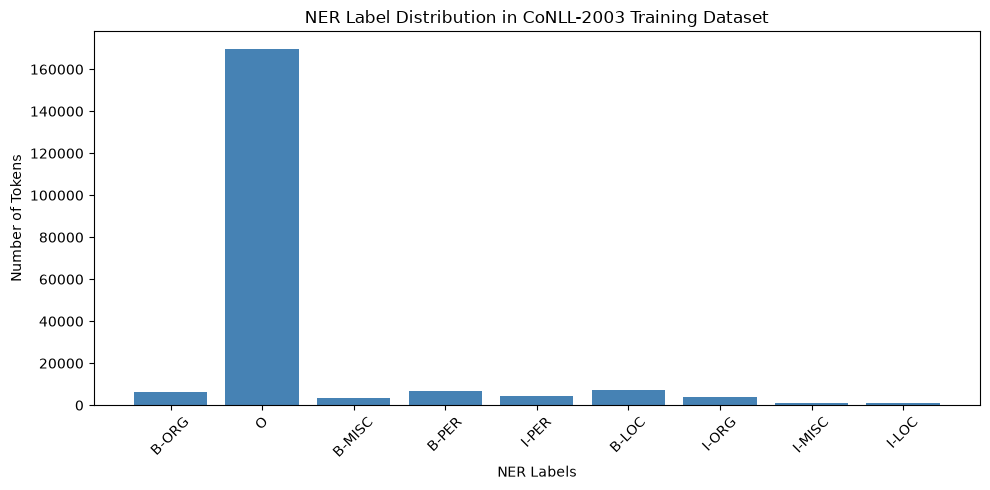

In [ ]:
import matplotlib.pyplot as plt

# Get labels and their counts
labels = list(label_counts.keys())
counts = list(label_counts.values())

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(labels, counts, color="steelblue")

plt.title("NER Label Distribution in CoNLL-2003 Training Dataset")
plt.xlabel("NER Labels")
plt.ylabel("Number of Tokens")

plt.xticks(rotation=45)

plt.tight_layout()

# Save the chart as a PNG image
plt.savefig("ner_label_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

In [15]:
import os
print(os.getcwd())

d:\PythonNER\NER-Personal-Information-Detection\notebooks


In [ ]:
from transformers import AutoTokenizer

# Load the BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

# Example sentence
text = "John works at Microsoft in London."

# Tokenise the sentence
tokens = tokenizer.tokenize(text)

print("Original text:", text)
print("BERT tokens:", tokens)

Original text: John works at Microsoft in London.
BERT tokens: ['John', 'works', 'at', 'Microsoft', 'in', 'London', '.']


In [ ]:
# Select an example from the training dataset
words = dataset["train"][0]["tokens"]

# Tokenise each word individually
for word in words:
    subwords = tokenizer.tokenize(word)
    print(word, "->", subwords)

EU -> ['EU']
rejects -> ['rejects']
German -> ['German']
call -> ['call']
to -> ['to']
boycott -> ['boycott']
British -> ['British']
lamb -> ['la', '##mb']
. -> ['.']


In [ ]:
# Get the first training example
words = dataset["train"][0]["tokens"]

# Tokenise the pre-split words
tokenized = tokenizer(
    words,
    is_split_into_words=True
)

# Display tokens and their original word IDs
tokens = tokenizer.convert_ids_to_tokens(tokenized["input_ids"])
word_ids = tokenized.word_ids()

for token, word_id in zip(tokens, word_ids):
    print(token, "-> Word ID:", word_id)

[CLS] -> Word ID: None
EU -> Word ID: 0
rejects -> Word ID: 1
German -> Word ID: 2
call -> Word ID: 3
to -> Word ID: 4
boycott -> Word ID: 5
British -> Word ID: 6
la -> Word ID: 7
##mb -> Word ID: 7
. -> Word ID: 8
[SEP] -> Word ID: None


In [20]:

# Get original NER labels
original_labels = dataset["train"][0]["ner_tags"]

# Align labels with BERT tokens
aligned_labels = []
previous_word_id = None

for word_id in word_ids:
    if word_id is None:
        aligned_labels.append(-100)

    elif word_id != previous_word_id:
        aligned_labels.append(original_labels[word_id])

    else:
        aligned_labels.append(-100)

    previous_word_id = word_id

# Display aligned tokens and labels
for token, label_id in zip(tokens, aligned_labels):
    label = "IGNORED" if label_id == -100 else label_names[label_id]
    print(token, "->", label)


[CLS] -> IGNORED
EU -> B-ORG
rejects -> O
German -> B-MISC
call -> O
to -> O
boycott -> O
British -> B-MISC
la -> O
##mb -> IGNORED
. -> O
[SEP] -> IGNORED


In [ ]:

# Function to tokenize words and align their NER labels
def tokenize_and_align_labels(examples):

    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True
    )

    all_labels = []

    for i, original_labels in enumerate(examples["ner_tags"]):

        word_ids = tokenized_inputs.word_ids(batch_index=i)

        aligned_labels = []
        previous_word_id = None

        for word_id in word_ids:

            if word_id is None:
                aligned_labels.append(-100)

            elif word_id != previous_word_id:
                aligned_labels.append(original_labels[word_id])

            else:
                aligned_labels.append(-100)

            previous_word_id = word_id

        all_labels.append(aligned_labels)

    tokenized_inputs["labels"] = all_labels

    return tokenized_inputs

In [ ]:
# Select one example and wrap it in a batch
sample = dataset["train"][0]

sample_batch = {
    "tokens": [sample["tokens"]],
    "ner_tags": [sample["ner_tags"]]
}

# Test the preprocessing function
processed_sample = tokenize_and_align_labels(sample_batch)

print("Input IDs:", processed_sample["input_ids"][0])
print("Aligned Labels:", processed_sample["labels"][0])

print(
    "Token count:",
    len(processed_sample["input_ids"][0])
)

print(
    "Label count:",
    len(processed_sample["labels"][0])
)

Input IDs: [101, 7270, 22961, 1528, 1840, 1106, 21423, 1418, 2495, 12913, 119, 102]
Aligned Labels: [-100, 3, 0, 7, 0, 0, 0, 7, 0, -100, 0, -100]
Token count: 12
Label count: 12


In [ ]:
# Apply preprocessing to the entire dataset
tokenized_dataset = dataset.map(
    tokenize_and_align_labels,
    batched=True
)

# Display the processed dataset structure
print(tokenized_dataset)

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3453
    })
})


In [ ]:

# Verify token-label alignment across all dataset splits
for split in ["train", "validation", "test"]:

    total_examples = len(tokenized_dataset[split])

    mismatches = 0

    for example in tokenized_dataset[split]:

        input_length = len(example["input_ids"])
        label_length = len(example["labels"])

        if input_length != label_length:
            mismatches += 1

    print(f"{split}:")
    print(f"  Total examples: {total_examples}")
    print(f"  Mismatched examples: {mismatches}")
    print()

train:
  Total examples: 14041
  Mismatched examples: 0

validation:
  Total examples: 3250
  Mismatched examples: 0

test:
  Total examples: 3453
  Mismatched examples: 0

